# FFOR pierpollo EV baseline grid 20_0

Notebook per calcolare la FFOR della rete `20_0` aggiungendo la baseline EV come carico fisso. HP, BESS, PV e algoritmo FFOR restano uguali alla versione `FFOR_pierpollo`.

Scelte operative lasciate come parametri in alto:
- i percorsi di input restano quelli del loader e dei file `20_0`;
- 8 direzioni dell'obiettivo: `0, 45, ..., 315` gradi, con pesi non normalizzati, per esempio `45 deg -> alpha=1, beta=1`;
- la FFOR e riportata in `pu`, come deviazione rispetto alla baseline del PCC inclusiva degli EV;
- convenzione paper/iniezione al PCC: consumo o import dalla HV negativo, generazione o export verso HV positivo;
- le colonne assolute usano quindi `P_pcc_injection_pu = -P_pcc_import_pu` e `Q_pcc_injection_pu = -Q_pcc_import_pu`;
- `P_flex_pu = P_pcc_injection_pu - P_base_injection_pu`, quindi `P_flex_pu > 0` significa aumento generazione o diminuzione consumo;
- `SOC_AT_T = 0.5` e usato solo come stato iniziale assunto nel timestep corrente;
- il timestep successivo delle BESS e limitato a `SOC_MIN = 0.40` e `SOC_MAX = 0.80`;
- le BESS sono modellate con una sola potenza attiva netta `bess_p`: `bess_p > 0` scarica, `bess_p < 0` carica;
- il vincolo SOC BESS non considera efficienze di carica/scarica: `SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh`;
- banda termica HP `19-21 C`, perche le foto danno la dinamica ma non i limiti di comfort.


In [ ]:
import json
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
from types import SimpleNamespace


GRID_NAME = os.getenv("FFOR_GRID_NAME", "20_0")
DATA_YEAR = int(os.getenv("FFOR_DATA_YEAR", "2050"))
TARGET_TIME = os.getenv("FFOR_TARGET_TIME", "12-01 15:00:00")
NEXT_TIME = os.getenv("FFOR_NEXT_TIME", TARGET_TIME)

SBASE_MVA = 100.0
SBASE_KW = SBASE_MVA * 1000.0
SBASE_KVAR = SBASE_MVA * 1000.0

PF_DER = 0.95
TAN_PHI = math.tan(math.acos(PF_DER))
DT_H = 0

SOC_AT_T = 0.60
SOC_MIN = 0.40
SOC_MAX = 0.80
T_SET_C = 20.0
T_MIN_C = 19.0
T_MAX_C = 21.0

N_POLY = 16
INNER_POLY_RADIUS = math.cos(math.pi / N_POLY)
FFOR_EPSILON = 1e-6

OUTPUT_DIR = Path("outputs") / f"ffor_quickflex_{GRID_NAME}_{DATA_YEAR}_{TARGET_TIME.replace(' ', '_').replace(':', '-')}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

print(f"FFOR run: grid={GRID_NAME}, year={DATA_YEAR}, target={TARGET_TIME}, output={OUTPUT_DIR}")


## 1. Baseline PCC

Il loader mantiene la convenzione dei profili: `P > 0` e consumo. Nel modello di rete sotto, invece, le variabili nodali dei DER sono in convenzione di iniezione: PV e BESS discharge positive, HP negative.

In [17]:
PROFILE_DIR = Path("outputs") / f"{GRID_NAME}_profiles_mveq_evbase_{DATA_YEAR}"
FFOR_INPUT_DIR = PROFILE_DIR / "ffor_inputs"

required_files = [
    PROFILE_DIR / "baseline_demand_total.csv",
    PROFILE_DIR / "hp_baseline_total.csv",
    PROFILE_DIR / "pv_generation_total.csv",
    PROFILE_DIR / "net_baseline_total.csv",
    PROFILE_DIR / "baseline_demand_by_mv_node.csv",
    PROFILE_DIR / "ev_baseline_total.csv",
    PROFILE_DIR / "ev_baseline_q_total.csv",
    PROFILE_DIR / "ev_baseline_by_mv_node.csv",
    PROFILE_DIR / "ev_baseline_q_by_mv_node.csv",
    PROFILE_DIR / "bess_allocation_mveq.csv",
    FFOR_INPUT_DIR / "nodes.csv",
    FFOR_INPUT_DIR / "connected_lv.csv",
    FFOR_INPUT_DIR / "pv_mv_generation.csv",
    FFOR_INPUT_DIR / "pv_lv_generation.csv",
    FFOR_INPUT_DIR / "hp_mv_allocation.csv",
    FFOR_INPUT_DIR / "hp_lv_allocation.csv",
    FFOR_INPUT_DIR / "temperature_profiles.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    missing_list = "\n".join(f"- {path}" for path in missing_files)
    raise FileNotFoundError(
        "Dati precomputati mancanti. Esegui prima:\n"
        "python loader_pierpollo_evbase.py --years 2030 2040 2050\n\n"
        f"File mancanti:\n{missing_list}"
    )

nodes = pd.read_csv(FFOR_INPUT_DIR / "nodes.csv", dtype={"osmid": str, "lv_grid": str})
baseline_demand_by_mv_node = pd.read_csv(PROFILE_DIR / "baseline_demand_by_mv_node.csv")
ev_baseline_by_mv_node = pd.read_csv(PROFILE_DIR / "ev_baseline_by_mv_node.csv")
ev_baseline_q_by_mv_node = pd.read_csv(PROFILE_DIR / "ev_baseline_q_by_mv_node.csv")
bess_allocation = pd.read_csv(PROFILE_DIR / "bess_allocation_mveq.csv")

mv_nodes_with_lv = nodes[nodes["lv_grid"].astype(str).ne("-1")].copy()
mv_to_lv = dict(zip(mv_nodes_with_lv["osmid"].astype(str), mv_nodes_with_lv["lv_grid"].astype(str)))
lv_to_mv = {lv_grid: mv_osmid for mv_osmid, lv_grid in mv_to_lv.items()}
loader = SimpleNamespace(
    nodes=nodes,
    baseline_demand_by_mv_node=baseline_demand_by_mv_node,
    ev_baseline_by_mv_node=ev_baseline_by_mv_node,
    ev_baseline_q_by_mv_node=ev_baseline_q_by_mv_node,
    bess_allocation=bess_allocation,
    mv_to_lv=mv_to_lv,
    lv_to_mv=lv_to_mv,
)

def total_profile_value(name, timestamp=TARGET_TIME):
    df = pd.read_csv(PROFILE_DIR / f"{name}.csv")
    return float(df.loc[df["Unnamed: 0"].eq(timestamp), "value_kW"].iloc[0])

baseline_demand_pcc_kW = total_profile_value("baseline_demand_total")
hp_baseline_pcc_kW = total_profile_value("hp_baseline_total")
pv_baseline_pcc_kW = total_profile_value("pv_generation_total")
ev_baseline_pcc_kW = total_profile_value("ev_baseline_total")
ev_baseline_pcc_kvar = float(pd.read_csv(PROFILE_DIR / "ev_baseline_q_total.csv").loc[lambda df: df["Unnamed: 0"].eq(TARGET_TIME), "value_kvar"].iloc[0])
net_baseline_pcc_profile_kW = total_profile_value("net_baseline_total")
net_baseline_with_ev_pcc_profile_kW = net_baseline_pcc_profile_kW + ev_baseline_pcc_kW
net_baseline_pcc_injection_kW = -net_baseline_with_ev_pcc_profile_kW

baseline_summary = pd.DataFrame([
    {"quantity": "conventional demand", "loader_value_kW": baseline_demand_pcc_kW, "injection_convention_kW": -baseline_demand_pcc_kW},
    {"quantity": "HP baseline demand", "loader_value_kW": hp_baseline_pcc_kW, "injection_convention_kW": -hp_baseline_pcc_kW},
    {"quantity": "PV baseline production", "loader_value_kW": pv_baseline_pcc_kW, "injection_convention_kW": pv_baseline_pcc_kW},
    {"quantity": "EV baseline demand", "loader_value_kW": ev_baseline_pcc_kW, "injection_convention_kW": -ev_baseline_pcc_kW},
    {"quantity": "EV baseline reactive", "loader_value_kW": ev_baseline_pcc_kvar, "injection_convention_kW": -ev_baseline_pcc_kvar},
    {"quantity": "net PCC baseline with EV", "loader_value_kW": net_baseline_with_ev_pcc_profile_kW, "injection_convention_kW": net_baseline_pcc_injection_kW},
])
baseline_summary


,quantity,loader_value_kW,injection_convention_kW
0,conventional demand,3042.121568,-3042.121568
1,HP baseline demand,756.381331,-756.381331
2,PV baseline production,92.827673,92.827673
3,EV baseline demand,149.296201,-149.296201
4,EV baseline reactive,49.071288,-49.071288
5,net PCC baseline with EV,3854.971427,-3854.971427


In [18]:
node_ids = [str(x) for x in loader.nodes["osmid"].astype(str)]
bus_ids = [int(x) + 1 for x in node_ids]
bus_to_pos = {bus: i for i, bus in enumerate(bus_ids)}
osmid_to_bus = {osmid: int(osmid) + 1 for osmid in node_ids}
n_bus = len(node_ids)

slack_bus = int(pd.read_excel("06_Grids/20_0_matpower.xlsx", sheet_name="generator_data").iloc[0]["GEN_BUS"])
slack_idx = bus_to_pos[slack_bus]
slack_osmid = str(slack_bus - 1)

print(f"MV nodes: {n_bus}")
print(f"Slack/PCC bus: MATPOWER {slack_bus}, MV_osmid {slack_osmid}")


MV nodes: 51
Slack/PCC bus: MATPOWER 45, MV_osmid 44


## 2. Asset DER e domanda fissa

- Domanda convenzionale: fissa, da `baseline_demand_by_mv_node`.
- EV baseline: fissa, da `ev_baseline_by_mv_node`, senza flessibilita; potenza reattiva da `pf = 0.95`.
- PV: `0 <= P <= P_base`, `|Q| <= P tan(acos(0.95))`.
- HP: variabile di iniezione negativa, `-P_peak/0.8 <= P <= 0`, `Q = P tan(acos(0.95))`, e vincolo termico sul passo successivo.
- BESS: `S_max = P_nom`, unica potenza netta `P_bess`; `P_bess > 0` scarica e `P_bess < 0` carica. Il SOC usa `SOC_next = SOC_AT_T - P_bess * DT_H / C`, senza efficienze.

In [19]:
def profile_by_node(df):
    out = df.copy()
    out["MV_osmid"] = out["MV_osmid"].astype(str)
    return out.set_index("MV_osmid")

demand_df = profile_by_node(loader.baseline_demand_by_mv_node)
ev_demand_df = profile_by_node(loader.ev_baseline_by_mv_node)
ev_q_df = profile_by_node(loader.ev_baseline_q_by_mv_node)

conventional_p_kW = np.array([
    float(demand_df.loc[osmid, TARGET_TIME]) if osmid in demand_df.index else 0.0
    for osmid in node_ids
])
ev_p_kW = np.array([
    float(ev_demand_df.loc[osmid, TARGET_TIME]) if osmid in ev_demand_df.index else 0.0
    for osmid in node_ids
])
fixed_p_kW = conventional_p_kW + ev_p_kW

bus_data = pd.read_csv("06_Grids/20_0_bus_data.csv")
bus_data["BUS_I"] = bus_data["BUS_I"].astype(int)
q_over_p = {
    int(row.BUS_I): (float(row.Qd) / float(row.Pd) if abs(float(row.Pd)) > 1e-12 else 0.0)
    for _, row in bus_data.iterrows()
}
conventional_q_kvar = np.array([
    conventional_p_kW[i] * q_over_p.get(bus_ids[i], 0.0)
    for i in range(n_bus)
])
ev_q_kvar = np.array([
    float(ev_q_df.loc[osmid, TARGET_TIME]) if osmid in ev_q_df.index else 0.0
    for osmid in node_ids
])
fixed_q_kvar = conventional_q_kvar + ev_q_kvar

print(f"Fixed conventional demand at {TARGET_TIME}: {conventional_p_kW.sum():.3f} kW, {conventional_q_kvar.sum():.3f} kvar")
print(f"Fixed EV baseline demand at {TARGET_TIME}: {ev_p_kW.sum():.3f} kW, {ev_q_kvar.sum():.3f} kvar")
print(f"Total fixed demand at {TARGET_TIME}: {fixed_p_kW.sum():.3f} kW, {fixed_q_kvar.sum():.3f} kvar")


Fixed conventional demand at 12-01 15:00:00: 3042.122 kW, 1473.367 kvar
Fixed EV baseline demand at 12-01 15:00:00: 149.296 kW, 49.071 kvar
Total fixed demand at 12-01 15:00:00: 3191.418 kW, 1522.438 kvar


In [20]:
connected_lv = set(loader.mv_to_lv.values())

pv_assets = []
path = FFOR_INPUT_DIR / "pv_mv_generation.csv"
if path.exists():
    mv_pv = pd.read_csv(path)
    for _, row in mv_pv.iterrows():
        mv_osmid = str(row["MV_osmid"])
        if mv_osmid not in osmid_to_bus:
            continue
        p_base = float(row.get(TARGET_TIME, 0.0) or 0.0)
        if p_base > 1e-9:
            pv_assets.append({"bus": osmid_to_bus[mv_osmid], "p_base_kW": p_base, "source": "MV"})

path = FFOR_INPUT_DIR / "pv_lv_generation.csv"
if path.exists():
    lv_pv = pd.read_csv(path)
    for _, row in lv_pv.iterrows():
        mv_osmid = loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue
        p_base = float(row.get(TARGET_TIME, 0.0) or 0.0)
        if p_base > 1e-9:
            pv_assets.append({"bus": osmid_to_bus[mv_osmid], "p_base_kW": p_base, "source": "LV"})

print(f"PV assets with nonzero production at {TARGET_TIME}: {len(pv_assets)}")
print(f"PV baseline production: {sum(a['p_base_kW'] for a in pv_assets):.3f} kW")


PV assets with nonzero production at 12-01 15:00:00: 306
PV baseline production: 92.828 kW


In [21]:
temperature_profiles = pd.read_csv(FFOR_INPUT_DIR / "temperature_profiles.csv").set_index("Temperature_profile_name")
time_columns = pd.read_csv(FFOR_INPUT_DIR / "time_columns.csv")["time_column"].astype(str).tolist()

def zero_series():
    return pd.Series(0.0, index=time_columns)

def hp_consumption_for_row(hp, temperature_profiles):
    profile_name = hp["Temperature_profile_name"]
    if profile_name not in temperature_profiles.index:
        return zero_series()

    temp = temperature_profiles.loc[profile_name, time_columns].astype(float)
    delta = T_SET_C - temp
    thermal_kw = float(hp["Thermal_conductivity_kW/K"]) * delta.clip(lower=0.0)

    if {"COP_0", "COP_1", "COP_2"}.issubset(hp.index) and not pd.isna(hp.get("COP_0")):
        cop = (
            float(hp["COP_0"])
            + float(hp["COP_1"]) * delta
            + float(hp["COP_2"]) * delta * delta
        ).clip(lower=1.0)
    else:
        cop = pd.Series(float(hp["COP"]), index=time_columns)

    electric_kw = thermal_kw / cop
    return electric_kw.clip(lower=0.0, upper=float(hp["Nominal_power_kW"]))

hp_assets = []
hp_skipped_zero_baseline = 0
for path, source in [
    (FFOR_INPUT_DIR / "hp_mv_allocation.csv", "MV"),
    (FFOR_INPUT_DIR / "hp_lv_allocation.csv", "LV"),
]:
    if not path.exists():
        continue
    hp = pd.read_csv(path)

    for _, row in hp.iterrows():
        mv_osmid = str(row["MV_osmid"]) if source == "MV" else loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue

        profile = hp_consumption_for_row(row, temperature_profiles)
        p_base = float(profile[TARGET_TIME])
        p_peak = float(profile.max())

        # No artificial HP start-up: if the heat pump is off in the baseline at TARGET_TIME,
        # it cannot provide flexibility in this single-timestep FFOR calculation.
        if p_base <= 1e-9:
            hp_skipped_zero_baseline += 1
            continue

        profile_name = row["Temperature_profile_name"]
        t_out = float(temperature_profiles.loc[profile_name, TARGET_TIME]) if profile_name in temperature_profiles.index else T_SET_C
        q_heat = (
            float(row["Thermal_conductivity_kW/K"])
            * max(T_SET_C - t_out, 0.0)
            / float(row["Thermal_capacitance_KWh/K"])
        )

        hp_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "p_base_kW": p_base,
            "p_peak_kW": p_peak,
            "q_heat_K_per_h": q_heat,
            "source": source,
        })

print(f"HP assets active at {TARGET_TIME}: {len(hp_assets)}")
print(f"HP skipped because baseline is zero: {hp_skipped_zero_baseline}")
print(f"HP baseline demand in flexible set: {sum(a['p_base_kW'] for a in hp_assets):.3f} kW")
print(f"HP annual baseline peak sum in flexible set: {sum(a['p_peak_kW'] for a in hp_assets):.3f} kW")


HP assets active at 12-01 15:00:00: 388
HP skipped because baseline is zero: 0
HP baseline demand in flexible set: 756.381 kW
HP annual baseline peak sum in flexible set: 1823.973 kW


In [22]:
bess_assets = []
for _, row in loader.bess_allocation.iterrows():
    mv_osmid = str(row["MV_osmid"])
    if mv_osmid in osmid_to_bus:
        bess_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "capacity_kWh": float(row["Battery_capacity_kWh"]),
            "p_nom_kW": float(row["Nominal_power_kW"]),
            "source_component": row["source_component"],
        })

print(f"BESS aggregate rows: {len(bess_assets)}")
print(f"BESS total P_nom: {sum(a['p_nom_kW'] for a in bess_assets):.3f} kW")
print(f"BESS total capacity: {sum(a['capacity_kWh'] for a in bess_assets):.3f} kWh")
print(f"BESS SOC at t: {SOC_AT_T:.0%}; next-step bounds: [{SOC_MIN:.0%}, {SOC_MAX:.0%}]")
print("BESS SOC model: SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh, no charge/discharge efficiencies")


BESS aggregate rows: 19
BESS total P_nom: 918.362 kW
BESS total capacity: 2295.905 kWh
BESS SOC at t: 60%; next-step bounds: [40%, 80%]
BESS SOC model: SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh, no charge/discharge efficiencies


## 3. Power flow linearizzato

Il Jacobiano segue le formule nelle immagini, linearizzato attorno a `V = 1 pu`, `theta = 0`. Per ogni linea uso `BR_R`, `BR_X`, `BR_B` dai file `20_0`, con `BR_B/2` come shunt per lato. I limiti apparenti di linea usano `s_nom` da `20_0_edges.txt` e un ottagono interno al cerchio.

In [23]:
branch = pd.read_csv("06_Grids/20_0_branch_data.csv")
branch = branch[branch["BR_STATUS"].astype(int).eq(1)].copy()

with open("06_Grids/20_0_edges.txt", "r") as f:
    edges_geojson = json.load(f)

line_s_nom_mva = {}
for feature in edges_geojson["features"]:
    props = feature["properties"]
    f_bus = int(props["u"]) + 1
    t_bus = int(props["v"]) + 1
    s_nom = float(props.get("s_nom", 0.0) or 0.0)
    line_s_nom_mva[(f_bus, t_bus)] = s_nom
    line_s_nom_mva[(t_bus, f_bus)] = s_nom

Jp_theta = np.zeros((n_bus, n_bus))
Jp_u = np.zeros((n_bus, n_bus))
Jq_u = np.zeros((n_bus, n_bus))
p_ref = np.zeros(n_bus)
q_ref = np.zeros(n_bus)
line_params = []

for _, row in branch.iterrows():
    f_bus = int(row["F_BUS"])
    t_bus = int(row["T_BUS"])
    if f_bus not in bus_to_pos or t_bus not in bus_to_pos:
        continue

    i = bus_to_pos[f_bus]
    k = bus_to_pos[t_bus]
    r = float(row["BR_R"])
    x = float(row["BR_X"])
    y = 1 / complex(r, x)
    g = y.real
    b = y.imag
    b_sh = float(row["BR_B"]) / 2.0

    Jp_theta[i, i] += -b
    Jp_theta[k, k] += -b
    Jp_theta[i, k] += b
    Jp_theta[k, i] += b

    Jp_u[i, i] += g
    Jp_u[k, k] += g
    Jp_u[i, k] += -g
    Jp_u[k, i] += -g

    Jq_u[i, i] += -2.0 * b_sh - b
    Jq_u[k, k] += -2.0 * b_sh - b
    Jq_u[i, k] += b
    Jq_u[k, i] += b

    q_ref[i] += -b_sh
    q_ref[k] += -b_sh

    line_params.append({
        "from_bus": f_bus,
        "to_bus": t_bus,
        "i": i,
        "k": k,
        "g": g,
        "b": b,
        "b_sh": b_sh,
        "s_nom_mva": line_s_nom_mva[(f_bus, t_bus)],
    })

Jq_theta = -Jp_u

print(f"Active MV branches: {len(line_params)}")
print(f"Line S_nom values in use: {sorted(set(p['s_nom_mva'] for p in line_params))} MVA")


Active MV branches: 50
Line S_nom values in use: [4.2, 4.4] MVA


## 4. LP della FFOR con Gurobi

Le variabili interne di slack `pcc_p_pu` e `pcc_q_pu` sono l'importazione dal PCC in per unit, perche questa e la forma naturale del bilancio costruito sopra. Subito dopo la soluzione, pero, ogni grandezza assoluta viene convertita nella convenzione del paper/iniezione:

`P_pcc_injection_pu = -P_pcc_import_pu`, `Q_pcc_injection_pu = -Q_pcc_import_pu`.

Il bus PCC ha `theta = 0` e `Delta U = 0`. Il modello resta lineare: le matrici dei vincoli vengono assemblate esplicitamente e poi passate a un modello Gurobi continuo.

In [24]:
idx = {}
bounds = []
var_names = []

def add_var(name, lb=None, ub=None):
    j = len(bounds)
    idx[name] = j
    var_names.append(name)
    bounds.append((lb, ub))
    return j

theta = [add_var(f"theta_{bus}", None, None) for bus in bus_ids]
du = [add_var(f"du_{bus}", -0.05, 0.05) for bus in bus_ids]
pcc_p = add_var("pcc_p_pu", None, None)
pcc_q = add_var("pcc_q_pu", None, None)

pv_p = []
pv_q = []
for a, asset in enumerate(pv_assets):
    p_base = asset["p_base_kW"]
    pv_p.append(add_var(f"pv_p_{a}", 0.0, p_base))
    pv_q.append(add_var(f"pv_q_{a}", -TAN_PHI * p_base, TAN_PHI * p_base))

hp_p = []
for a, asset in enumerate(hp_assets):
    hp_p.append(add_var(f"hp_p_{a}", -asset["p_peak_kW"] / 0.9, 0.0))

bess_p = []
bess_q = []
for a, asset in enumerate(bess_assets):
    p_nom = asset["p_nom_kW"]
    # bess_p is the net active power at the grid side:
    #   bess_p > 0 -> discharge / injection
    #   bess_p < 0 -> charge / consumption
    bess_p.append(add_var(f"bess_p_{a}", -p_nom, p_nom))
    bess_q.append(add_var(f"bess_q_{a}", -p_nom, p_nom))

n_var = len(bounds)

def zero_row():
    return np.zeros(n_var)

A_eq = []
b_eq = []
A_ub = []
b_ub = []
ub_names = []

def add_eq(coefs, rhs):
    row = zero_row()
    for j, value in coefs.items():
        row[j] += value
    A_eq.append(row)
    b_eq.append(rhs)

def add_ub(coefs, rhs, name="unnamed inequality"):
    row = zero_row()
    for j, value in coefs.items():
        row[j] += value
    A_ub.append(row)
    b_ub.append(rhs)
    ub_names.append(name)

pv_by_bus = {bus: [] for bus in bus_ids}
hp_by_bus = {bus: [] for bus in bus_ids}
bess_by_bus = {bus: [] for bus in bus_ids}
for a, asset in enumerate(pv_assets):
    pv_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(hp_assets):
    hp_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(bess_assets):
    bess_by_bus[asset["bus"]].append(a)

# Slack bus constraint.
add_eq({theta[slack_idx]: 1.0}, 0.0)
add_eq({du[slack_idx]: 1.0}, 0.0)

# Linearized nodal power flow, all buses including the slack.
for i, bus in enumerate(bus_ids):
    coefs = {}
    if i == slack_idx:
        coefs[pcc_p] = 1.0
    for a in pv_by_bus[bus]:
        coefs[pv_p[a]] = coefs.get(pv_p[a], 0.0) + 1.0 / SBASE_KW
    for a in hp_by_bus[bus]:
        coefs[hp_p[a]] = coefs.get(hp_p[a], 0.0) + 1.0 / SBASE_KW
    for a in bess_by_bus[bus]:
        coefs[bess_p[a]] = coefs.get(bess_p[a], 0.0) + 1.0 / SBASE_KW
    for k in range(n_bus):
        if abs(Jp_theta[i, k]) > 0.0:
            coefs[theta[k]] = coefs.get(theta[k], 0.0) - Jp_theta[i, k]
        if abs(Jp_u[i, k]) > 0.0:
            coefs[du[k]] = coefs.get(du[k], 0.0) - Jp_u[i, k]
    add_eq(coefs, p_ref[i] + fixed_p_kW[i] / SBASE_KW)

    coefs = {}
    if i == slack_idx:
        coefs[pcc_q] = 1.0
    for a in pv_by_bus[bus]:
        coefs[pv_q[a]] = coefs.get(pv_q[a], 0.0) + 1.0 / SBASE_KVAR
    for a in hp_by_bus[bus]:
        coefs[hp_p[a]] = coefs.get(hp_p[a], 0.0) + TAN_PHI / SBASE_KVAR
    for a in bess_by_bus[bus]:
        coefs[bess_q[a]] = coefs.get(bess_q[a], 0.0) + 1.0 / SBASE_KVAR
    for k in range(n_bus):
        if abs(Jq_theta[i, k]) > 0.0:
            coefs[theta[k]] = coefs.get(theta[k], 0.0) - Jq_theta[i, k]
        if abs(Jq_u[i, k]) > 0.0:
            coefs[du[k]] = coefs.get(du[k], 0.0) - Jq_u[i, k]
    add_eq(coefs, q_ref[i] + fixed_q_kvar[i] / SBASE_KVAR)

# PV triangular PF capability.
for a, asset in enumerate(pv_assets):
    bus = asset["bus"]
    add_ub(
        {pv_q[a]: 1.0, pv_p[a]: -TAN_PHI},
        0.0,
        name=f"Limite Q massimo PV asset {a} al bus {bus}",
    )
    add_ub(
        {pv_q[a]: -1.0, pv_p[a]: -TAN_PHI},
        0.0,
        name=f"Limite Q minimo PV asset {a} al bus {bus}",
    )

# HP next-step temperature constraint.
for a, asset in enumerate(hp_assets):
    p_base = asset["p_base_kW"]
    q_heat = asset["q_heat_K_per_h"]
    if p_base > 1e-9 and q_heat > 1e-12:
        coeff = q_heat * DT_H / p_base
        bus = asset["bus"]
        add_ub(
            {hp_p[a]: -coeff},
            T_MAX_C - T_SET_C + coeff * p_base,
            name=f"Limite sovratemperatura HP asset {a} al bus {bus}",
        )
        add_ub(
            {hp_p[a]: coeff},
            T_SET_C - T_MIN_C - coeff * p_base,
            name=f"Limite sottotemperatura HP asset {a} al bus {bus}",
        )

# BESS apparent power polygon and SOC next-step constraints with one net active power variable.
normals = [
    (math.cos(2.0 * math.pi * j / N_POLY + math.pi / N_POLY), math.sin(2.0 * math.pi * j / N_POLY + math.pi / N_POLY))
    for j in range(N_POLY)
]

for a, asset in enumerate(bess_assets):
    p_nom = asset["p_nom_kW"]
    cap = asset["capacity_kWh"]

    # SOC model without charge/discharge efficiencies:
    # SOC_next = SOC_AT_T - bess_p * DT_H / cap
    # bess_p > 0 discharges the battery -> SOC decreases.
    # bess_p < 0 charges the battery -> SOC increases.
    bus = asset["bus"]
    add_ub(
        {bess_p[a]: -DT_H / cap},
        SOC_MAX - SOC_AT_T,
        name=f"Limite SOC massimo BESS asset {a} al bus {bus}",
    )
    add_ub(
        {bess_p[a]: DT_H / cap},
        SOC_AT_T - SOC_MIN,
        name=f"Limite SOC minimo BESS asset {a} al bus {bus}",
    )

    for normal_id, (n_p, n_q) in enumerate(normals):
        normal_angle_deg = (math.degrees(math.atan2(n_q, n_p)) + 360.0) % 360.0
        add_ub(
            {bess_p[a]: n_p, bess_q[a]: n_q},
            p_nom * INNER_POLY_RADIUS,
            name=(
                f"Limite potenza apparente BESS asset {a} al bus {bus} "
                f"(faccia {normal_id}, normale {normal_angle_deg:.1f} deg)"
            ),
        )

# Line apparent power polygon, both directions.
def add_line_side(i, k, g, b, b_sh, s_lim_pu):
    from_bus = bus_ids[i]
    to_bus = bus_ids[k]
    for normal_id, (n_p, n_q) in enumerate(normals):
        coefs = {
            theta[i]: -n_p * b - n_q * g,
            theta[k]: n_p * b + n_q * g,
            du[i]: n_p * g - n_q * (2.0 * b_sh + b),
            du[k]: -n_p * g + n_q * b,
        }
        rhs = s_lim_pu * INNER_POLY_RADIUS + n_q * b_sh
        normal_angle_deg = (math.degrees(math.atan2(n_q, n_p)) + 360.0) % 360.0
        add_ub(
            coefs,
            rhs,
            name=(
                f"Limite potenza linea {from_bus} -> {to_bus} "
                f"(faccia {normal_id}, normale {normal_angle_deg:.1f} deg)"
            ),
        )

for params in line_params:
    s_lim_pu = params["s_nom_mva"] / SBASE_MVA
    add_line_side(params["i"], params["k"], params["g"], params["b"], params["b_sh"], s_lim_pu)
    add_line_side(params["k"], params["i"], params["g"], params["b"], params["b_sh"], s_lim_pu)

A_eq = np.vstack(A_eq)
b_eq = np.array(b_eq)
A_ub = np.vstack(A_ub)
b_ub = np.array(b_ub)

print(f"Variables: {n_var}")
print(f"Equalities: {len(b_eq)}")
print(f"Inequalities: {len(b_ub)}")


Variables: 1142
Equalities: 104
Inequalities: 3330


In [25]:
def line_flow_values(x):
    flows = []
    for params in line_params:
        for direction, i, k in [
            ("from_to", params["i"], params["k"]),
            ("to_from", params["k"], params["i"]),
        ]:
            theta_ik = x[theta[i]] - x[theta[k]]
            du_ik = x[du[i]] - x[du[k]]
            p_pu = -params["b"] * theta_ik + params["g"] * du_ik
            q_pu = -params["b_sh"] * (1.0 + 2.0 * x[du[i]]) - params["b"] * du_ik - params["g"] * theta_ik
            s_mva = math.hypot(p_pu * SBASE_MVA, q_pu * SBASE_MVA)
            flows.append({
                "from_bus": bus_ids[i],
                "to_bus": bus_ids[k],
                "direction": direction,
                "p_mw": p_pu * SBASE_MVA,
                "q_mvar": q_pu * SBASE_MVA,
                "s_mva": s_mva,
                "s_nom_mva": params["s_nom_mva"],
                "loading_ratio": s_mva / params["s_nom_mva"],
            })
    return pd.DataFrame(flows)

def summarize_solution(x):
    flows = line_flow_values(x)
    return {
        "P_pcc_pu": float(x[pcc_p]),
        "Q_pcc_pu": float(x[pcc_q]),
        "V_min_pu": 1.0 + float(x[du].min()),
        "V_max_pu": 1.0 + float(x[du].max()),
        "line_loading_max": float(flows["loading_ratio"].max()),
    }

BINDING_TOL = 1e-6


def _readable_bound_name(j, side):
    if j in du:
        bus = bus_ids[du.index(j)]
        return f"Limite sottotensione bus {bus}" if side == "lower" else f"Limite sovratensione bus {bus}"
    if j in pv_p:
        a = pv_p.index(j)
        bus = pv_assets[a]["bus"]
        return f"Limite P minimo PV asset {a} al bus {bus}" if side == "lower" else f"Limite P disponibile PV asset {a} al bus {bus}"
    if j in pv_q:
        a = pv_q.index(j)
        bus = pv_assets[a]["bus"]
        return f"Limite Q minimo variabile PV asset {a} al bus {bus}" if side == "lower" else f"Limite Q massimo variabile PV asset {a} al bus {bus}"
    if j in hp_p:
        a = hp_p.index(j)
        bus = hp_assets[a]["bus"]
        return f"Limite massimo consumo HP asset {a} al bus {bus}" if side == "lower" else f"Limite spegnimento/minimo consumo HP asset {a} al bus {bus}"
    if j in bess_p:
        a = bess_p.index(j)
        bus = bess_assets[a]["bus"]
        return f"Limite carica BESS asset {a} al bus {bus}" if side == "lower" else f"Limite scarica BESS asset {a} al bus {bus}"
    if j in bess_q:
        a = bess_q.index(j)
        bus = bess_assets[a]["bus"]
        return f"Limite Q assorbita BESS asset {a} al bus {bus}" if side == "lower" else f"Limite Q iniettata BESS asset {a} al bus {bus}"
    return f"Limite {'inferiore' if side == 'lower' else 'superiore'} variabile {var_names[j]}"


def binding_constraints_for_solution(x, tol=BINDING_TOL):
    rows = []

    for j, (lb, ub) in enumerate(bounds):
        if lb is not None:
            slack = float(x[j] - lb)
            if slack <= max(tol, tol * max(1.0, abs(float(lb)), abs(float(x[j])))):
                rows.append({
                    "kind": "variable_bound",
                    "constraint": _readable_bound_name(j, "lower"),
                    "value": float(x[j]),
                    "limit": float(lb),
                    "slack": slack,
                })
        if ub is not None:
            slack = float(ub - x[j])
            if slack <= max(tol, tol * max(1.0, abs(float(ub)), abs(float(x[j])))):
                rows.append({
                    "kind": "variable_bound",
                    "constraint": _readable_bound_name(j, "upper"),
                    "value": float(x[j]),
                    "limit": float(ub),
                    "slack": slack,
                })

    lhs = A_ub @ x
    for row_id, (lhs_value, rhs, name) in enumerate(zip(lhs, b_ub, ub_names)):
        lhs_value = float(lhs_value)
        rhs = float(rhs)
        slack = rhs - lhs_value
        if slack <= max(tol, tol * max(1.0, abs(rhs), abs(lhs_value))):
            rows.append({
                "kind": "inequality",
                "constraint": name,
                "value": lhs_value,
                "limit": rhs,
                "slack": slack,
            })

    if not rows:
        return pd.DataFrame(columns=["kind", "constraint", "value", "limit", "slack"])
    return pd.DataFrame(rows).sort_values(["slack", "constraint"]).reset_index(drop=True)


def _constraint_group(name):
    if "sottotensione" in name or "sovratensione" in name:
        return "voltage"
    if "potenza linea" in name:
        return "line"
    if "potenza apparente BESS" in name:
        return "bess_power"
    if "SOC" in name:
        return "bess_soc"
    if "BESS" in name:
        return "bess_bound"
    if "PV" in name:
        return "pv_bound"
    if "HP" in name:
        return "hp_bound"
    return "other"


def _print_binding_rows(rows, max_rows):
    for _, row in rows.head(max_rows).iterrows():
        print(
            f"    - {row['constraint']} "
            f"| valore={row['value']:.6g}, limite={row['limit']:.6g}, slack={row['slack']:.2e}"
        )
    if len(rows) > max_rows:
        print(f"    ... altri {len(rows) - max_rows} non mostrati")


def _active_asset_ids(active, asset_label):
    if active.empty:
        return set()
    ids = active["constraint"].astype(str).str.extract(rf"{asset_label} asset (\d+)", expand=False).dropna()
    return set(ids.astype(int))


def _asset_binding_status(active, asset_label, asset_count):
    if asset_count == 0:
        return "nessun asset presente"
    active_count = len(_active_asset_ids(active, asset_label))
    answer = "si" if active_count == asset_count else "no"
    return f"{answer} ({active_count}/{asset_count})"


def print_binding_constraints(x, label, tol=BINDING_TOL, max_network_rows=30):
    active = binding_constraints_for_solution(x, tol=tol)
    print(f"\nVincoli binding per {label}")
    if active.empty:
        print("  - Line/voltage constraints binding: nessuno")
        print("  - DER binding sintetico:")
        print(f"    - Tutti BESS binding: {_asset_binding_status(active, 'BESS', len(bess_assets))}")
        print(f"    - Tutti HP binding: {_asset_binding_status(active, 'HP', len(hp_assets))}")
        print(f"    - Tutti PV binding: {_asset_binding_status(active, 'PV', len(pv_assets))}")
        return active

    active = active.copy()
    active["group"] = active["constraint"].map(_constraint_group)

    network = active[active["group"].isin(["voltage", "line"])]
    if network.empty:
        print("  - Line/voltage constraints binding: nessuno")
    else:
        print(f"  - Line/voltage constraints binding: {len(network)}")
        _print_binding_rows(network, max_network_rows)

    print("  - DER binding sintetico:")
    print(f"    - Tutti BESS binding: {_asset_binding_status(active, 'BESS', len(bess_assets))}")
    print(f"    - Tutti HP binding: {_asset_binding_status(active, 'HP', len(hp_assets))}")
    print(f"    - Tutti PV binding: {_asset_binding_status(active, 'PV', len(pv_assets))}")
    return active


def _gurobi_bound(value, sign):
    if value is None:
        return -GRB.INFINITY if sign < 0 else GRB.INFINITY
    return float(value)

def _expr_from_dense_row(row, variables, tol=1e-12):
    nz = np.flatnonzero(np.abs(row) > tol)
    return gp.quicksum(float(row[j]) * variables[j] for j in nz)

def solve_with_bounds(c, local_bounds, A_eq_local=None, b_eq_local=None, A_ub_local=None, b_ub_local=None, model_name="ffor_lp"):
    A_eq_use = A_eq if A_eq_local is None else A_eq_local
    b_eq_use = b_eq if b_eq_local is None else b_eq_local
    A_ub_use = A_ub if A_ub_local is None else A_ub_local
    b_ub_use = b_ub if b_ub_local is None else b_ub_local

    model = gp.Model(model_name)
    model.Params.OutputFlag = 0

    x_vars = []
    for j, (lb, ub) in enumerate(local_bounds):
        x_vars.append(model.addVar(
            lb=_gurobi_bound(lb, -1),
            ub=_gurobi_bound(ub, 1),
            vtype=GRB.CONTINUOUS,
            name=f"x_{j}",
        ))
    model.update()

    for row, rhs in zip(A_eq_use, b_eq_use):
        model.addConstr(_expr_from_dense_row(row, x_vars) == float(rhs))
    for row, rhs in zip(A_ub_use, b_ub_use):
        model.addConstr(_expr_from_dense_row(row, x_vars) <= float(rhs))

    obj_nz = np.flatnonzero(np.abs(c) > 1e-12)
    model.setObjective(gp.quicksum(float(c[j]) * x_vars[j] for j in obj_nz), GRB.MINIMIZE)
    model.optimize()

    status_name = {
        GRB.OPTIMAL: "optimal",
        GRB.INFEASIBLE: "infeasible",
        GRB.INF_OR_UNBD: "infeasible_or_unbounded",
        GRB.UNBOUNDED: "unbounded",
        GRB.TIME_LIMIT: "time_limit",
    }.get(model.Status, f"gurobi_status_{model.Status}")

    if model.Status == GRB.OPTIMAL:
        return SimpleNamespace(
            success=True,
            message=status_name,
            status=model.Status,
            obj=float(model.ObjVal),
            x=np.array([var.X for var in x_vars], dtype=float),
        )

    return SimpleNamespace(
        success=False,
        message=status_name,
        status=model.Status,
        obj=np.nan,
        x=np.full(len(local_bounds), np.nan),
    )


## 5. Baseline coerente col power flow lineare

Qui fisso i DER al loro valore baseline: PV alla produzione baseline, HP al consumo baseline, BESS a zero. La baseline finale riportata sotto e in convenzione a iniezione: consumo/import negativo, generazione/export positiva.

In [26]:
baseline_bounds = list(bounds)
for a, asset in enumerate(pv_assets):
    baseline_bounds[pv_p[a]] = (asset["p_base_kW"], asset["p_base_kW"])
    baseline_bounds[pv_q[a]] = (0.0, 0.0)
for a, asset in enumerate(hp_assets):
    baseline_bounds[hp_p[a]] = (-asset["p_base_kW"], -asset["p_base_kW"])
for a in range(len(bess_assets)):
    for j in [bess_p[a], bess_q[a]]:
        baseline_bounds[j] = (0.0, 0.0)

baseline_result = solve_with_bounds(np.zeros(n_var), baseline_bounds, model_name="baseline_pf_network_constrained")
BASELINE_NETWORK_FEASIBLE = baseline_result.success
BASELINE_STATUS = "network_feasible"

if not baseline_result.success:
    print(
        "Baseline fixed-DER PF infeasible with voltage/line limits; "
        "using relaxed-network baseline only as PCC reference."
    )
    relaxed_baseline_bounds = list(baseline_bounds)
    for j in du:
        relaxed_baseline_bounds[j] = (None, None)
    empty_A_ub = np.zeros((0, n_var))
    empty_b_ub = np.zeros(0)
    baseline_result = solve_with_bounds(
        np.zeros(n_var),
        relaxed_baseline_bounds,
        A_ub_local=empty_A_ub,
        b_ub_local=empty_b_ub,
        model_name="baseline_pf_relaxed_network",
    )
    BASELINE_STATUS = "network_infeasible_relaxed_pf"
    if not baseline_result.success:
        raise RuntimeError(f"Baseline PF infeasible even after relaxing network limits: {baseline_result.message}")

baseline_pf = summarize_solution(baseline_result.x)
P_BASE_IMPORT_PU = baseline_pf["P_pcc_pu"]
Q_BASE_IMPORT_PU = baseline_pf["Q_pcc_pu"]
P_BASE_INJECTION_PU = -P_BASE_IMPORT_PU
Q_BASE_INJECTION_PU = -Q_BASE_IMPORT_PU

baseline_pf_summary = pd.DataFrame([{
    "baseline_status": BASELINE_STATUS,
    "baseline_network_feasible": BASELINE_NETWORK_FEASIBLE,
    "P_base_profile_injection_pu": -net_baseline_with_ev_pcc_profile_kW / SBASE_KW,
    "P_base_linear_pf_injection_pu": P_BASE_INJECTION_PU,
    "Q_base_linear_pf_injection_pu": Q_BASE_INJECTION_PU,
    "P_base_import_internal_pu": P_BASE_IMPORT_PU,
    "Q_base_import_internal_pu": Q_BASE_IMPORT_PU,
    "V_min_pu": baseline_pf["V_min_pu"],
    "V_max_pu": baseline_pf["V_max_pu"],
    "line_loading_max": baseline_pf["line_loading_max"],
}])
baseline_pf_summary


,P_base_profile_injection_pu,P_base_linear_pf_injection_pu,Q_base_linear_pf_injection_pu,P_base_import_internal_pu,Q_base_import_internal_pu,V_min_pu,V_max_pu,line_loading_max
0,-0.03855,-0.03855,-0.016306,0.03855,0.016306,0.994419,1.0,0.591353


## 6. Esplorazione delle 8 direzioni via obiettivo alpha/beta

Per ogni direzione imposto i pesi dell'obiettivo `alpha, beta` in forma non normalizzata:

- `0 deg`: `alpha=1`, `beta=0`;
- `45 deg`: `alpha=1`, `beta=1`;
- `90 deg`: `alpha=0`, `beta=1`;
- `135 deg`: `alpha=-1`, `beta=1`;
- `180 deg`: `alpha=-1`, `beta=0`;
- `225 deg`: `alpha=-1`, `beta=-1`;
- `270 deg`: `alpha=0`, `beta=-1`;
- `315 deg`: `alpha=1`, `beta=-1`.

Poi massimizzo:

`alpha * P_flex + beta * Q_flex`

con `P_flex = P_pcc_injection - P_base_injection` e `Q_flex = Q_pcc_injection - Q_base_injection`.

Poiche il solver interno minimizza e le variabili PCC interne sono import positive, l'obiettivo equivalente passato a Gurobi e:

`min alpha * P_pcc_import + beta * Q_pcc_import`.


In [27]:
INITIAL_DIRECTIONS = [
    ("min_P", 1.0, 0.0),
    ("min_Q", 0.0, 1.0),
    ("max_P", -1.0, 0.0),
    ("max_Q", 0.0, -1.0),
]

POINT_TOL = 1e-9
MAX_FFOR_ITERATIONS = 200


def solve_direction(alpha, beta, model_name="ffor_direction"):
    """Minimize alpha*P_flex + beta*Q_flex.

    Internally P_flex = -pcc_p - constant and Q_flex = -pcc_q - constant,
    so constants drop out and the Gurobi objective uses -alpha and -beta
    on the PCC import variables.
    """
    c = np.zeros(n_var)
    c[pcc_p] = -alpha
    c[pcc_q] = -beta
    result = solve_with_bounds(c, bounds, model_name=model_name)
    if not result.success:
        return SimpleNamespace(success=False, message=result.message, alpha=alpha, beta=beta)

    x = result.x[:n_var]
    summary = summarize_solution(x)
    p_pcc_injection = -summary["P_pcc_pu"]
    q_pcc_injection = -summary["Q_pcc_pu"]
    p_flex = p_pcc_injection - P_BASE_INJECTION_PU
    q_flex = q_pcc_injection - Q_BASE_INJECTION_PU

    summary.update({
        "status": "optimal",
        "alpha": alpha,
        "beta": beta,
        "objective_value_pu": alpha * p_flex + beta * q_flex,
        "P_flex_pu": p_flex,
        "Q_flex_pu": q_flex,
        "P_pcc_injection_pu": p_pcc_injection,
        "Q_pcc_injection_pu": q_pcc_injection,
        "P_base_injection_pu": P_BASE_INJECTION_PU,
        "Q_base_injection_pu": Q_BASE_INJECTION_PU,
        "P_pcc_import_internal_pu": summary["P_pcc_pu"],
        "Q_pcc_import_internal_pu": summary["Q_pcc_pu"],
        "point_angle_deg": (
            (math.degrees(math.atan2(q_flex, p_flex)) + 360.0) % 360.0
            if math.hypot(p_flex, q_flex) > 1e-12 else np.nan
        ),
    })
    binding_df = binding_constraints_for_solution(x)
    binding_groups = binding_df["constraint"].map(_constraint_group) if not binding_df.empty else pd.Series(dtype=object)
    summary["binding_constraints_count"] = len(binding_df)
    summary["binding_network_constraints_count"] = int(binding_groups.isin(["voltage", "line"]).sum())
    return SimpleNamespace(success=True, message="optimal", x=x, summary=summary)


def point_key(point, digits=10):
    point = np.asarray(point, dtype=float)
    return tuple(np.round(point, digits))


def convex_hull(points):
    """Monotone-chain convex hull, returned counterclockwise without repeat."""
    unique = sorted({point_key(p): tuple(np.asarray(p, dtype=float)) for p in points}.values())
    if len(unique) <= 1:
        return [np.asarray(p, dtype=float) for p in unique]

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

    lower = []
    for p in unique:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 1e-12:
            lower.pop()
        lower.append(p)

    upper = []
    for p in reversed(unique):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 1e-12:
            upper.pop()
        upper.append(p)

    return [np.asarray(p, dtype=float) for p in lower[:-1] + upper[:-1]]


def polygon_area(points):
    if len(points) < 3:
        return 0.0
    pts = np.asarray(points, dtype=float)
    x = pts[:, 0]
    y = pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def outward_normal_for_segment(A, B, polygon_points):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    d = B - A
    norm = np.linalg.norm(d)
    if norm <= 0.0:
        raise ValueError("Segment has zero length.")

    n = np.array([-d[1], d[0]], dtype=float) / norm
    centroid = np.mean(np.asarray(polygon_points, dtype=float), axis=0)
    midpoint = 0.5 * (A + B)

    if np.dot(n, centroid - midpoint) > 0.0:
        n = -n
    return n


def add_solution_point(points, point_solutions, sol, source, iteration, segment_id=""):
    point = np.array([sol.summary["P_flex_pu"], sol.summary["Q_flex_pu"]], dtype=float)
    key = point_key(point)
    if key not in point_solutions:
        point_solutions[key] = {
            "point": point,
            "x": sol.x,
            "summary": sol.summary,
            "source": source,
            "iteration": iteration,
            "segment_id": segment_id,
        }
        points.append(point)
        return True, key
    return False, key


points = []
point_solutions = {}
search_log = []

for name, alpha, beta in INITIAL_DIRECTIONS:
    sol = solve_direction(alpha, beta, model_name=f"ffor_initial_{name}")
    if not sol.success:
        raise RuntimeError(f"Initial direction {name} failed: {sol.message}")
    add_solution_point(points, point_solutions, sol, source=name, iteration=0)

inactive_segments = set()
iteration = 1
while iteration <= MAX_FFOR_ITERATIONS:
    hull = convex_hull(points)
    area_before = polygon_area(hull)
    added_this_iteration = False

    for edge_idx in range(len(hull)):
        A = hull[edge_idx]
        B = hull[(edge_idx + 1) % len(hull)]
        segment_key = (point_key(A), point_key(B))
        if segment_key in inactive_segments:
            continue

        n = outward_normal_for_segment(A, B, hull)
        sol = solve_direction(-n[0], -n[1], model_name=f"ffor_segment_{iteration}_{edge_idx}")
        if not sol.success:
            inactive_segments.add(segment_key)
            search_log.append({
                "iteration": iteration,
                "edge_idx": edge_idx,
                "status": sol.message,
                "distance_pu": np.nan,
                "area_increase": 0.0,
            })
            continue

        X = np.array([sol.summary["P_flex_pu"], sol.summary["Q_flex_pu"]], dtype=float)
        distance = float(np.dot(n, X - A))
        new_points = points + [X]
        area_after = polygon_area(convex_hull(new_points))
        area_increase = (area_after - area_before) / area_after if area_after > 0.0 else 0.0

        search_log.append({
            "iteration": iteration,
            "edge_idx": edge_idx,
            "status": "optimal",
            "A_P_flex_pu": A[0],
            "A_Q_flex_pu": A[1],
            "B_P_flex_pu": B[0],
            "B_Q_flex_pu": B[1],
            "normal_P": n[0],
            "normal_Q": n[1],
            "alpha": -n[0],
            "beta": -n[1],
            "P_new_flex_pu": X[0],
            "Q_new_flex_pu": X[1],
            "distance_pu": distance,
            "area_before_pu2": area_before,
            "area_after_pu2": area_after,
            "area_increase": area_increase,
        })

        if distance > FFOR_EPSILON:
            added, _ = add_solution_point(
                points,
                point_solutions,
                sol,
                source="segment_search",
                iteration=iteration,
                segment_id=f"{iteration}_{edge_idx}",
            )
            if added:
                added_this_iteration = True
        else:
            inactive_segments.add(segment_key)

    if not added_this_iteration:
        break
    iteration += 1

final_hull = convex_hull(points)
final_hull_keys = [point_key(p) for p in final_hull]

rows = []
solutions = {}
for point_id, key in enumerate(final_hull_keys):
    entry = point_solutions[key]
    row = dict(entry["summary"])
    row.update({
        "point_id": point_id,
        "source": entry["source"],
        "iteration": entry["iteration"],
        "segment_id": entry["segment_id"],
    })
    rows.append(row)
    solutions[point_id] = entry["x"]

ffor_points = pd.DataFrame(rows)
ffor_points = ffor_points[[
    "point_id", "source", "iteration", "segment_id", "status", "alpha", "beta", "objective_value_pu",
    "P_flex_pu", "Q_flex_pu", "P_pcc_injection_pu", "Q_pcc_injection_pu",
    "P_base_injection_pu", "Q_base_injection_pu",
    "P_pcc_import_internal_pu", "Q_pcc_import_internal_pu",
    "point_angle_deg", "V_min_pu", "V_max_pu", "line_loading_max",
    "binding_constraints_count", "binding_network_constraints_count"
]]

search_log_df = pd.DataFrame(search_log)
print(f"QuickFlex points in final hull: {len(ffor_points)}")
print(f"Segment-search iterations: {iteration}")
print(f"Final hull area: {polygon_area(final_hull):.8f} pu^2")
ffor_points


QuickFlex points in final hull: 21
Segment-search iterations: 4
Final hull area: 0.00068516 pu^2


,point_id,source,iteration,segment_id,status,alpha,beta,objective_value_pu,P_flex_pu,Q_flex_pu,...,P_base_injection_pu,Q_base_injection_pu,P_pcc_import_internal_pu,Q_pcc_import_internal_pu,point_angle_deg,V_min_pu,V_max_pu,line_loading_max,binding_constraints_count,binding_network_constraints_count
0,0,min_P,0,,optimal,1.000000,0.000000,-0.022814,-0.022814,-0.004181,...,-0.03855,-0.016306,0.061364,0.020488,190.386006,0.992099,1.0,0.780266,1363,0
1,1,segment_search,2,2_0,optimal,0.923883,0.382675,-0.023377,-0.022115,-0.007696,...,-0.03855,-0.016306,0.060665,0.024002,199.187934,0.992019,1.0,0.787290,1344,0
2,2,segment_search,1,1_0,optimal,0.684229,0.729267,-0.021555,-0.020125,-0.010675,...,-0.03855,-0.016306,0.058674,0.026981,207.944437,0.992086,1.0,0.774859,1344,0
3,3,segment_search,2,2_1,optimal,0.374041,0.927412,-0.018159,-0.017145,-0.012666,...,-0.03855,-0.016306,0.055695,0.028972,216.454373,0.992289,1.0,0.743981,1344,0
4,4,segment_search,3,3_3,optimal,0.220261,0.975441,-0.016224,-0.016217,-0.012971,...,-0.03855,-0.016306,0.054767,0.029277,218.653439,0.992364,1.0,0.733166,1344,0
5,5,min_Q,0,,optimal,0.000000,1.000000,-0.013669,-0.012703,-0.013669,...,-0.03855,-0.016306,0.051252,0.029975,227.098566,0.992673,1.0,0.695973,1363,0
6,6,segment_search,2,2_2,optimal,-0.295928,0.955210,-0.009669,-0.009188,-0.012969,...,-0.03855,-0.016306,0.047738,0.029275,234.683309,0.993039,1.0,0.674363,1344,0
7,7,segment_search,1,1_1,optimal,-0.474078,0.880483,-0.010800,0.011078,-0.006302,...,-0.03855,-0.016306,0.027471,0.022608,330.367977,0.995097,1.0,0.557119,1344,0
8,8,segment_search,2,2_3,optimal,-0.831615,0.555352,-0.014084,0.014058,-0.004310,...,-0.03855,-0.016306,0.024492,0.020616,342.955668,0.995466,1.0,0.534469,1344,0
9,9,segment_search,3,3_7,optimal,-0.923959,0.382492,-0.015337,0.016048,-0.001329,...,-0.03855,-0.016306,0.022501,0.017636,355.264330,0.995754,1.0,0.513993,1344,0


## Vincoli binding per punto FFOR

Output sintetico per ciascun punto finale della frontiera: dettagli solo per vincoli di linea/tensione; DER indicati solo se tutti gli asset della categoria sono binding.


In [28]:
binding_constraint_tables = []
binding_network_tables = []
binding_summary_rows = []

for _, point_row in ffor_points.iterrows():
    point_id = int(point_row["point_id"])
    label = (
        f"punto {point_id} "
        f"(P_flex={point_row['P_flex_pu']:.6g} pu, "
        f"Q_flex={point_row['Q_flex_pu']:.6g} pu, "
        f"angolo={point_row['point_angle_deg']:.3f} deg)"
    )
    active = print_binding_constraints(solutions[point_id], label)
    if active.empty:
        group_counts = pd.Series(dtype=int)
        active_with_point = active.copy()
    else:
        active_with_point = active.copy()
        if "group" not in active_with_point.columns:
            active_with_point["group"] = active_with_point["constraint"].map(_constraint_group)
        active_with_point.insert(0, "point_id", point_id)
        active_with_point.insert(1, "P_flex_pu", point_row["P_flex_pu"])
        active_with_point.insert(2, "Q_flex_pu", point_row["Q_flex_pu"])
        active_with_point.insert(3, "point_angle_deg", point_row["point_angle_deg"])
        binding_constraint_tables.append(active_with_point)
        network = active_with_point[active_with_point["group"].isin(["voltage", "line"])]
        if not network.empty:
            binding_network_tables.append(network)
        group_counts = active_with_point["group"].value_counts()

    binding_summary_rows.append({
        "point_id": point_id,
        "P_flex_pu": point_row["P_flex_pu"],
        "Q_flex_pu": point_row["Q_flex_pu"],
        "point_angle_deg": point_row["point_angle_deg"],
        "line_voltage_binding": int(group_counts.get("line", 0) + group_counts.get("voltage", 0)),
        "all_bess_binding": _asset_binding_status(active, "BESS", len(bess_assets)),
        "all_hp_binding": _asset_binding_status(active, "HP", len(hp_assets)),
        "all_pv_binding": _asset_binding_status(active, "PV", len(pv_assets)),
    })

binding_constraints_by_point = (
    pd.concat(binding_constraint_tables, ignore_index=True)
    if binding_constraint_tables
    else pd.DataFrame(columns=["point_id", "P_flex_pu", "Q_flex_pu", "point_angle_deg", "kind", "constraint", "value", "limit", "slack", "group"])
)
binding_network_constraints_by_point = (
    pd.concat(binding_network_tables, ignore_index=True)
    if binding_network_tables
    else pd.DataFrame(columns=["point_id", "P_flex_pu", "Q_flex_pu", "point_angle_deg", "kind", "constraint", "value", "limit", "slack", "group"])
)
binding_summary_by_point = pd.DataFrame(binding_summary_rows)

binding_summary_by_point.to_csv(OUTPUT_DIR / "binding_summary_by_point.csv", index=False)
binding_constraints_by_point.to_csv(OUTPUT_DIR / "binding_constraints_by_point.csv", index=False)
binding_network_constraints_by_point.to_csv(OUTPUT_DIR / "binding_network_constraints_by_point.csv", index=False)

print(f"Saved binding constraint outputs in: {OUTPUT_DIR}")
display(binding_summary_by_point)
display(binding_network_constraints_by_point[[
    "point_id", "P_flex_pu", "Q_flex_pu", "point_angle_deg",
    "constraint", "value", "limit", "slack"
]])



Vincoli binding per punto 0 (P_flex=-0.0228144 pu, Q_flex=-0.00418147 pu, angolo=190.386 deg)
  - Line/voltage constraints binding: nessuno
  - DER binding sintetico:
    - Tutti BESS binding: si (19/19)
    - Tutti HP binding: si (388/388)
    - Tutti PV binding: si (306/306)

Vincoli binding per punto 1 (P_flex=-0.0221154 pu, Q_flex=-0.00769617 pu, angolo=199.188 deg)
  - Line/voltage constraints binding: nessuno
  - DER binding sintetico:
    - Tutti BESS binding: si (19/19)
    - Tutti HP binding: si (388/388)
    - Tutti PV binding: si (306/306)

Vincoli binding per punto 2 (P_flex=-0.0201246 pu, Q_flex=-0.0106754 pu, angolo=207.944 deg)
  - Line/voltage constraints binding: nessuno
  - DER binding sintetico:
    - Tutti BESS binding: si (19/19)
    - Tutti HP binding: si (388/388)
    - Tutti PV binding: si (306/306)

Vincoli binding per punto 3 (P_flex=-0.0171452 pu, Q_flex=-0.0126657 pu, angolo=216.454 deg)
  - Line/voltage constraints binding: nessuno
  - DER binding sintetic

,point_id,P_flex_pu,Q_flex_pu,point_angle_deg,line_voltage_binding,all_bess_binding,all_hp_binding,all_pv_binding
0,0,-0.022814,-0.004181,190.386006,0,si (19/19),si (388/388),si (306/306)
1,1,-0.022115,-0.007696,199.187934,0,si (19/19),si (388/388),si (306/306)
2,2,-0.020125,-0.010675,207.944437,0,si (19/19),si (388/388),si (306/306)
3,3,-0.017145,-0.012666,216.454373,0,si (19/19),si (388/388),si (306/306)
4,4,-0.016217,-0.012971,218.653439,0,si (19/19),si (388/388),si (306/306)
5,5,-0.012703,-0.013669,227.098566,0,si (19/19),si (388/388),si (306/306)
6,6,-0.009188,-0.012969,234.683309,0,si (19/19),si (388/388),si (306/306)
7,7,0.011078,-0.006302,330.367977,0,si (19/19),si (388/388),si (306/306)
8,8,0.014058,-0.004310,342.955668,0,si (19/19),si (388/388),si (306/306)
9,9,0.016048,-0.001329,355.264330,0,si (19/19),si (388/388),si (306/306)


,point_id,P_flex_pu,Q_flex_pu,point_angle_deg,constraint,value,limit,slack


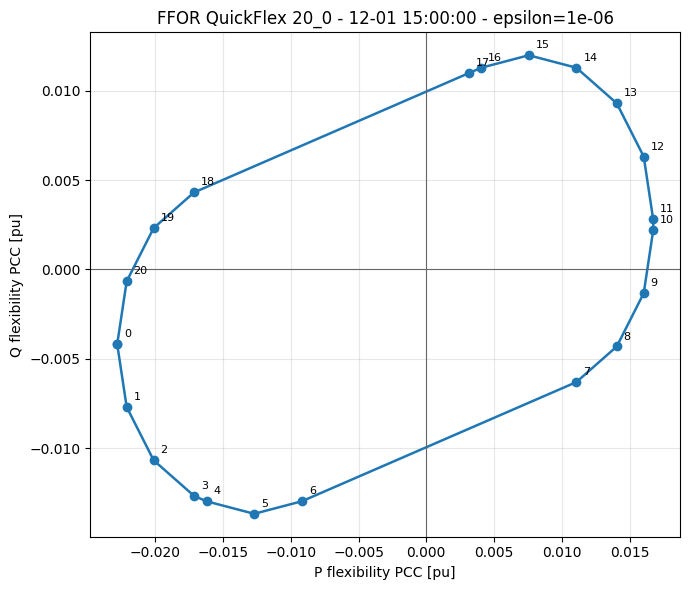

Saved outputs in: outputs\ffor_quickflex_20_0_2030_12-01_15-00-00


In [29]:
closed_points = ffor_points.copy()
if not closed_points.empty:
    first = closed_points.iloc[[0]].copy()
    first["point_id"] = len(closed_points)
    closed_points = pd.concat([closed_points, first], ignore_index=True)

ffor_points.to_csv(OUTPUT_DIR / "ffor_boundary_points.csv", index=False)
closed_points.to_csv(OUTPUT_DIR / "ffor_boundary_closed.csv", index=False)
search_log_df.to_csv(OUTPUT_DIR / "ffor_segment_search_log.csv", index=False)
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
baseline_pf_summary.to_csv(OUTPUT_DIR / "baseline_pf_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(closed_points["P_flex_pu"], closed_points["Q_flex_pu"], marker="o", linewidth=1.8)
for _, row in ffor_points.iterrows():
    ax.annotate(
        str(int(row["point_id"])),
        (row["P_flex_pu"], row["Q_flex_pu"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )
ax.axhline(0.0, color="0.4", linewidth=0.8)
ax.axvline(0.0, color="0.4", linewidth=0.8)
ax.set_xlabel("P flexibility PCC [pu]")
ax.set_ylabel("Q flexibility PCC [pu]")
ax.set_title(f"FFOR QuickFlex {GRID_NAME} - {TARGET_TIME} - epsilon={FFOR_EPSILON:g}")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ffor_polygon_delta_pq.png", dpi=160)
plt.show()

print(f"Saved outputs in: {OUTPUT_DIR}")


In [30]:
# Optional detail: line loading at each optimized boundary point.
line_flow_tables = []
for point_id, x in solutions.items():
    flows = line_flow_values(x)
    flows.insert(0, "point_id", point_id)
    line_flow_tables.append(flows)

if line_flow_tables:
    line_flows = pd.concat(line_flow_tables, ignore_index=True)
    line_flows.to_csv(OUTPUT_DIR / "line_flows_by_boundary_point.csv", index=False)
    display(line_flows.sort_values("loading_ratio", ascending=False).head(10))


,point_id,from_bus,to_bus,direction,p_mw,q_mvar,s_mva,s_nom_mva,loading_ratio
134,1,9,45,from_to,-3.107406,-1.130383,3.306620,4.2,0.787290
135,1,45,9,to_from,3.107406,1.129343,3.306264,4.2,0.787206
34,0,9,45,from_to,-3.158347,-0.874261,3.277115,4.2,0.780266
35,0,45,9,to_from,3.158347,0.873220,3.276838,4.2,0.780199
234,2,9,45,from_to,-2.962338,-1.347485,3.254406,4.2,0.774859
235,2,45,9,to_from,2.962338,1.346444,3.253976,4.2,0.774756
2034,20,9,45,from_to,-3.107406,-0.618109,3.168285,4.2,0.754354
2035,20,45,9,to_from,3.107406,0.617068,3.168082,4.2,0.754305
334,3,9,45,from_to,-2.745229,-1.492513,3.124720,4.2,0.743981
335,3,45,9,to_from,2.745229,1.491472,3.124223,4.2,0.743863
